# CS-781 Capstone — Phase 1, Step 1: Data Exploration

**Goal:** understand the Phase-1 corpus _before_ choosing a tokenizer or model.

We answer five questions:

1. Which files exist and how big are they? (→ how many tokens can we afford?)
2. What does one record look like? (→ field names, file format)
3. How long are documents in each source — Acts / High Courts / Supreme Court / Tribunals? (→ mixing strategy, context length)
4. What does the raw text look like? (→ cleaning needed?)
5. What do the **test prompts** look like? (→ what our model must actually do)

**One rule for this whole notebook:** never load a multi-GB file fully into RAM.
Free Colab gives ~12 GB RAM. A 5 GB JSON file turned into Python objects by `json.load` can need 3–5× its size in memory → the runtime crashes.
So we only _peek_ (read the first few KB) or _stream_ (read records one at a time).


## 0. Setup

`!` runs a shell command from inside the notebook. `-q` = quiet. Colab/Kaggle usually already have these libraries; this line just makes sure.


In [1]:
!pip install -q huggingface_hub ijson matplotlib tqdm


[notice] A new release of pip is available: 23.2.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


### Login (only if needed)

If a later cell fails with **401 / "gated repo" / "unauthorized"**, the dataset needs a Hugging Face account.
Make a _Read_ token at https://huggingface.co/settings/tokens, uncomment `login()`, run it and paste the token.
(A token is just a password for scripts. Never put it inside code you submit or push to GitHub.)


In [2]:
from huggingface_hub import login
# login()   # <- uncomment only if you get an authorization error

### Cache helper: never redo a finished step

Streaming thousands of documents takes minutes. `cached(name, compute)` saves each result as a JSON file in `experiments/data_exploration/`.
If the file already exists, it's **loaded** instead of recomputed, so re-running the notebook is instant. Delete a file to force that step to run again.
`tqdm` draws the progress bars (`tqdm.auto` picks the nice notebook version automatically).


In [3]:
import os, json
from tqdm.auto import tqdm

from pathlib import Path

# Find the project root: walk up from this notebook's folder until we see .gitignore.
# Works no matter how deep the notebook sits (notebooks/, notebooks/Phase 1/, ...).
PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / ".gitignore").exists():
    if PROJECT_ROOT.parent == PROJECT_ROOT:            # reached the top of the drive -> not found
        raise FileNotFoundError("Project root with .gitignore not found")
    PROJECT_ROOT = PROJECT_ROOT.parent
print("Project root:", PROJECT_ROOT)

CACHE_DIR = str(PROJECT_ROOT / "experiments" / "data_exploration")
os.makedirs(CACHE_DIR, exist_ok=True)

def cached(name, compute):
    # Load result `name` from disk if it exists; otherwise run compute(), save it, and return it.
    path = os.path.join(CACHE_DIR, f"{name}.json")
    if os.path.exists(path):
        print(f"[cache] loaded {name}")
        with open(path, encoding="utf-8") as f:
            return json.load(f)
    result = compute()
    with open(path, "w", encoding="utf-8") as f:
        json.dump(result, f, ensure_ascii=False)
    print(f"[cache] saved {name}")
    return result

Project root: c:\Users\Atharva\Desktop\Assignments\LLM\Capstone Project


c:\Users\Atharva\Desktop\Assignments\LLM\Capstone Project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1.1 List every file and its size — without downloading anything

`HfApi` talks to the Hugging Face Hub's web API. `list_repo_tree` returns **metadata only** (path + size), so this is instant.

**Why sizes matter:** a rough rule for English text is **~4 bytes ≈ 1 BPE token**. So file size ÷ 4 gives a ballpark token count per source.
(It over-estimates a bit, because JSON also stores keys, quotes and escape characters.)
This tells us what fraction of the 4.5B-token corpus we can realistically train on with free GPUs (spoiler: a small fraction, a few hundred million tokens).


In [4]:
from huggingface_hub import HfApi

REPO_ID = "Exploration-Lab/CS-781-Capstone"   # official dataset (capstone document, section 5)
api = HfApi()                                  # client object for the Hub's web API

# recursive=True  -> also look inside sub-folders
# repo_type="dataset" -> this is a dataset repo (default would be a *model* repo)
def list_files():
    entries = api.list_repo_tree(REPO_ID, repo_type="dataset", recursive=True)
    # folders have no .size -> getattr returns None -> skipped
    return [(e.path, e.size) for e in entries if getattr(e, "size", None) is not None]

all_files = cached("repo_files", list_files)
for path, size in all_files:
    print(f"{size/1e9:8.3f} GB   {path}")

phase1_files = [(p, s) for p, s in all_files if "Phase_1" in p]   # reused in later cells

print("\nPhase-1 files (rough token estimate = bytes / 4):")
for path, size in phase1_files:
    print(f"  {path:60s} {size/1e9:6.2f} GB   ~{size/4/1e9:5.2f} B tokens")

[cache] saved repo_files
   0.000 GB   .gitattributes
   0.003 GB   Phase_1_Pretraining/Test/test.json
   0.729 GB   Phase_1_Pretraining/Train/train_acts.json
  10.672 GB   Phase_1_Pretraining/Train/train_high_courts.json
   1.323 GB   Phase_1_Pretraining/Train/train_supreme_court.json
   6.484 GB   Phase_1_Pretraining/Train/train_tribunals.json
   0.001 GB   Phase_2_LNER/Test/fold3-text.json
   0.000 GB   Phase_2_LNER/Train/fold1-gold.json
   0.001 GB   Phase_2_LNER/Train/fold1-text.json
   0.000 GB   Phase_2_LNER/Train/fold2-gold.json
   0.001 GB   Phase_2_LNER/Train/fold2-text.json
   0.000 GB   Phase_2_LNER/Train/labels.txt
   0.000 GB   Phase_3_RR/Test/CL_test.json
   0.000 GB   Phase_3_RR/Test/IT_test.json
   0.000 GB   Phase_3_RR/Train/CL_dev.json
   0.002 GB   Phase_3_RR/Train/CL_train.json
   0.000 GB   Phase_3_RR/Train/IT_dev.json
   0.002 GB   Phase_3_RR/Train/IT_train.json
   0.000 GB   Phase_3_RR/Train/label_vocab.json
   0.035 GB   Phase_4_CJPE/Test/test.json
   0.080 GB 

## 1.2 Peek at the first 1500 bytes of each Phase-1 file

`HfFileSystem` lets us treat the Hub like a normal disk. `f.read(1500)` downloads **only the first 1500 bytes** (an HTTP "range request"), not the whole file.

How to read what you see:

| File starts with…                      | Format                          | Meaning for us                               |
| -------------------------------------- | ------------------------------- | -------------------------------------------- |
| `[{"...`                               | one big JSON **array**          | can't be read line-by-line; careful with RAM |
| `{"...}` then a newline, then `{"...}` | **JSONL** (one record per line) | easy to stream                               |
| `{"1": {"text": ...`                   | JSON **dict** keyed by id       | same shape as the test file / submission     |
| `PAR1`                                 | Parquet (binary)                | fine, `datasets` handles it                  |

**Write down:** the format, and the exact field names (e.g. `"text"`, `"id"`, maybe a court/year field).


In [5]:
from huggingface_hub import HfFileSystem

fs = HfFileSystem()   # filesystem-like access to the Hub: fs.open, fs.ls, ...

def peek(path_in_repo, n_bytes=1500):
    # Print only the first n_bytes of a remote file (no full download).
    full_path = f"datasets/{REPO_ID}/{path_in_repo}"   # HfFileSystem path format: datasets/<repo>/<file>
    with fs.open(full_path, "rb") as f:                # "rb" = read raw bytes
        head = f.read(n_bytes)
    print("=" * 100)
    print(path_in_repo)
    print("=" * 100)
    # bytes -> text. errors="replace": if we cut a multi-byte character (e.g. Hindi) in half, show ? instead of crashing
    print(head.decode("utf-8", errors="replace"))

for path, _ in phase1_files:
    peek(path)

Phase_1_Pretraining/Test/test.json
{
  "1": {
    "text": "The issue involved in these petitions is as to whether the acquisition proceedings can be challenged at a belated stage. The issue is no more res integra as the issue has been considered by this Court time and again. 6. When a person challenges Section 4 Notification on any ground, it should be challenged within a reasonable period, and if the acquisition is challenged at a belated stage, the petition deserves to be dismissed only on this count. (Vide Hari Singh & Ors. Vs. State of U.P., AIR 1984 SC 1020). 7. A Constitution Bench of this Court, in [Aflatoon & Ors. Vs. Lt. Governor, Delhi & Ors.] AIR 1974 SC 2077, while dealing with the issue, observed as under:- \".... to have sat on the fence and allowed the government to complete the acquisition on the basis that notification under Section 4 and the declaration under Section 6 were valid and then to attack the notification on the grounds which were available to them at the ti

## 1.3 Stream records one by one with `ijson`

The starter notebook confirms the format: each training file is **one big JSON array** of records like `{"text": "..."}`,
and the test file is a dict `{"1": {"text": ...}, ...}`.

A JSON array can't be read line by line, and `json.load` needs the whole file in RAM (the High Courts file is many GB).
`ijson` is a **streaming JSON parser**: it reads the file as a stream of bytes and hands us one complete record at a time.
Combined with `HfFileSystem`, we read straight from the Hub — only the bytes we actually consume are downloaded.

`ijson.items(f, "item")` means: "give me each element (`item`) of the top-level array". This is a Python **generator**:
it produces values lazily, so memory stays small no matter how big the file is.


In [6]:
import ijson

TEXT_FIELD = "text"   # confirmed by the starter notebook: data["text"]
TRAIN_FILES = [p for p, _ in phase1_files if "/Train/" in p]
TEST_FILE   = [p for p, _ in phase1_files if "/Test/" in p][0]
print("train files:", TRAIN_FILES)
print("test file  :", TEST_FILE)

def stream_records(path_in_repo):
    # Yield records of a remote JSON array one at a time (generator -> constant memory).
    full_path = f"datasets/{REPO_ID}/{path_in_repo}"
    with fs.open(full_path, "rb", block_size=2**20) as f:   # read the remote file in 1 MB pieces
        for rec in ijson.items(f, "item"):                   # "item" = each element of the top-level array
            yield rec

for path in TRAIN_FILES:
    first = next(stream_records(path))       # next() pulls exactly ONE record
    print(f"\n--- {path} ---")
    for key, value in first.items():
        print(f"  {key!r:12} ({type(value).__name__}): {str(value)[:300]!r}")

train files: ['Phase_1_Pretraining/Train/train_acts.json', 'Phase_1_Pretraining/Train/train_high_courts.json', 'Phase_1_Pretraining/Train/train_supreme_court.json', 'Phase_1_Pretraining/Train/train_tribunals.json']
test file  : Phase_1_Pretraining/Test/test.json

--- Phase_1_Pretraining/Train/train_acts.json ---
  'title'      (str): 'Bangalore City Planning Area Zonal Regulations (Amendment and Validation) Act, 1996'
  'category'   (str): 'Greater Bengaluru City Corporation - Act'
  'year'       (int): '1972'
  'url'        (str): 'https://indiankanoon.org/doc/179573747/'
  'text'       (str): 'Bangalore City Planning Area Zonal Regulations (Amendment and Validation) Act, 1996 (Karnataka Act No. 2 of 1996) Statements of objects and Reasons - Act 2 of 1996. - The Bangalore City Planning Area Zonal Regulations 1972, which was in vogue till 1984, provided for construction of five floors inclu'
  'word_count' (int): '1277'
  'text_length_chars' (int): '7784'

--- Phase_1_Pretraining/Train

## 1.4 Document-length statistics per source

**Why:**

- The task is **512 words in → 128 words out**, so a training document should ideally be ≥ 640 words to look like a test example. We count how many are shorter.
- Length differences between Acts / HC / SC / Tribunals tell us how much text each source really contributes → input for the **data-mixing** experiments.
- We measure in **whitespace words** (not tokens) because that's the unit the task uses. `chars/word` will later help us compare tokenizers.

**Sampling:** reading every document would take hours. We read the first `SCAN_DOCS` documents and keep every `STEP`-th one (systematic sampling) → `SCAN_DOCS / STEP` docs per source.
Limitation (write it in the report): this only covers the _beginning_ of each file; if a file is sorted by year or court, the sample is biased.


In [7]:
import numpy as np
from itertools import islice   # islice(iterator, start, stop, step) = slicing for generators

SCAN_DOCS = 10_000   # how far into each file we read
STEP = 5             # keep every 5th doc -> 2000 docs per source

def length_stats(path):
    words, chars = [], []
    sample = islice(stream_records(path), 0, SCAN_DOCS, STEP)
    for rec in tqdm(sample, total=SCAN_DOCS // STEP, desc=path.split("/")[-1]):   # progress bar
        text = rec.get(TEXT_FIELD) or ""      # "or ''" guards against missing/None text
        words.append(len(text.split()))       # .split() with no argument splits on any whitespace
        chars.append(len(text))
    return {"words": words, "chars": chars}   # plain lists -> can be saved as JSON

stats = {}
for path in TRAIN_FILES:
    name = path.split("/")[-1]                 # e.g. train_supreme_court.json
    r = cached(f"lengths_{name}", lambda: length_stats(path))
    w, c = np.array(r["words"]), np.array(r["chars"])
    stats[name] = w
    print(f"\n{name}: {len(w)} docs sampled")
    print(f"  words/doc : mean={w.mean():,.0f}  median={np.median(w):,.0f}  "
          f"p10={np.percentile(w, 10):,.0f}  p90={np.percentile(w, 90):,.0f}  max={w.max():,}")
    print(f"  chars/word: {c.sum() / max(w.sum(), 1):.2f}")
    print(f"  docs shorter than 640 words (512 prompt + 128 continuation): {(w < 640).mean() * 100:.1f}%")

train_acts.json: 100%|██████████| 2000/2000 [07:55<00:00,  4.21it/s]


[cache] saved lengths_train_acts.json

train_acts.json: 2000 docs sampled
  words/doc : mean=6,277  median=2,583  p10=412  p90=14,681  max=178,954
  chars/word: 6.00
  docs shorter than 640 words (512 prompt + 128 continuation): 17.9%


train_high_courts.json: 100%|██████████| 2000/2000 [00:32<00:00, 61.43it/s]


[cache] saved lengths_train_high_courts.json

train_high_courts.json: 2000 docs sampled
  words/doc : mean=458  median=289  p10=89  p90=800  max=19,750
  chars/word: 5.97
  docs shorter than 640 words (512 prompt + 128 continuation): 85.2%


train_supreme_court.json: 100%|██████████| 2000/2000 [04:51<00:00,  6.87it/s]


[cache] saved lengths_train_supreme_court.json

train_supreme_court.json: 2000 docs sampled
  words/doc : mean=4,069  median=2,312  p10=492  p90=8,004  max=356,601
  chars/word: 5.91
  docs shorter than 640 words (512 prompt + 128 continuation): 14.8%


train_tribunals.json: 100%|██████████| 2000/2000 [03:35<00:00,  9.29it/s]

[cache] saved lengths_train_tribunals.json

train_tribunals.json: 2000 docs sampled
  words/doc : mean=2,998  median=1,559  p10=281  p90=6,866  max=64,355
  chars/word: 6.06
  docs shorter than 640 words (512 prompt + 128 continuation): 27.6%


### Plot for the report

Document lengths span from tens to hundreds of thousands of words, so a normal histogram would squash everything into one bar.
We plot **log10(words)**: 2 = 100 words, 3 = 1,000 words, 4 = 10,000 words.


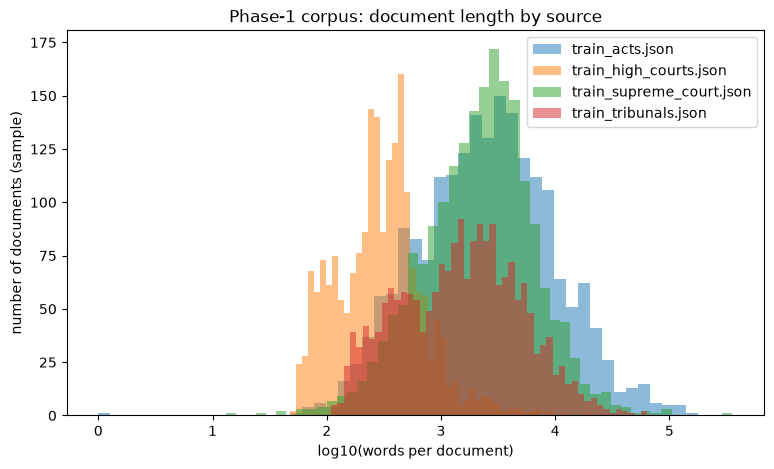

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))
for s, w in stats.items():
    plt.hist(np.log10(w + 1), bins=50, alpha=0.5, label=s)   # +1 avoids log10(0) for empty docs
plt.xlabel("log10(words per document)")
plt.ylabel("number of documents (sample)")
plt.title("Phase-1 corpus: document length by source")
plt.legend()
plt.savefig(os.path.join(CACHE_DIR, "doc_lengths.png"), dpi=150, bbox_inches="tight")   # saved file -> use it in the LaTeX report
plt.show()

## 1.5 Read real text with your own eyes

Numbers hide problems. For one arbitrary document per source we print the **beginning** (usually case title, parties, bench) and a chunk from the **middle** (the actual legal reasoning).

Look for: OCR noise, page headers/footers ("Page 3 of 20"), line numbers, Hindi/Devanagari text, tables, repeated boilerplate.
Anything you find here is a candidate **preprocessing** step — and a good sentence for the report.


In [9]:
for path in TRAIN_FILES:
    rec = next(islice(stream_records(path), 777, None))   # skip 777 docs, take the next one (an arbitrary document)
    text = rec[TEXT_FIELD]
    s = path.split("/")[-1]
    mid = len(text) // 2                                         # // = integer division
    print("=" * 100); print(s); print("=" * 100)
    print(text[:600])
    print("\n   [ ... ]\n")
    print(text[mid: mid + 900])
    print()

train_acts.json
The Maharashtra (Bombay Area) Emergency Malaria Regulations, 1973 Published vide Notification G. N., U. D. P. H. & H. D., No. PHD. 1672/7659-D, dated 2nd May, 1973 (M. G., Part 4-A, page 324)[Under the Epidemic Diseases (Bombay Amendment) Act, 1953] Whereas, the Government of Maharashtra is satisfied that the Bombay Area of the State of Maharashtra is infected by and is threatened with an outbreak of malaria; And whereas, the Government of Maharashtra thinks that the ordinary provisions of law for the time being in force in the Bombay area are insufficient to prevent the outbreak and spread of

   [ ... ]

 latter district for publication whenever and wherever necessary, a list of infected towns and villages in the infected area. The Collector of the contiguous district on receipt of the list of the towns and villages in the infected area shall forward a copy of the list to such local authorities in his district as he may deem fit.
6. Notification of persons suffering f

## 1.6 Simple quality checks

- **Exact duplicates:** we fingerprint each text with MD5 (a hash: same text → same 32-char code). Duplicates make the model memorize, and if a duplicate lands in both train and validation, validation loss looks better than it really is.
- **Very short docs (< 50 words):** often junk (empty orders, headers only).
- **Non-ASCII share:** Hindi text, curly quotes, `§`, `₹`… A high share affects tokenizer design.

This only checks within a 2000-doc sample, so it _underestimates_ duplication in the full file. Say so in the report.


In [10]:
import hashlib, re

NON_ASCII = re.compile(r"[^\x00-\x7F]")   # regex: any character outside the basic ASCII range 0-127

def quality_report(path, n=2000):
    seen, n_dup, n_short, non_ascii, total = set(), 0, 0, 0, 0
    for rec in tqdm(islice(stream_records(path), n), total=n, desc=path.split("/")[-1]):   # first n docs
        text = rec[TEXT_FIELD] or ""
        h = hashlib.md5(text.encode("utf-8")).hexdigest()   # fingerprint of the whole text
        n_dup += h in seen                                  # True counts as 1, False as 0
        seen.add(h)
        n_short += len(text.split()) < 50
        non_ascii += len(NON_ASCII.findall(text))
        total += len(text)
    return [n_dup, n_short, non_ascii / max(total, 1)]

for path in TRAIN_FILES:
    name = path.split("/")[-1]
    d, sh, na = cached(f"quality_{name}", lambda: quality_report(path))
    print(f"{path.split('/')[-1]:28s}  exact dups: {d:4d}   <50-word docs: {sh:4d}   non-ASCII chars: {na * 100:.2f}%")

train_acts.json: 100%|██████████| 2000/2000 [01:14<00:00, 26.71it/s]


[cache] saved quality_train_acts.json
train_acts.json               exact dups:    0   <50-word docs:    1   non-ASCII chars: 0.00%


train_high_courts.json: 100%|██████████| 2000/2000 [00:07<00:00, 262.01it/s]


[cache] saved quality_train_high_courts.json
train_high_courts.json        exact dups:    0   <50-word docs:    5   non-ASCII chars: 0.05%


train_supreme_court.json: 100%|██████████| 2000/2000 [01:11<00:00, 27.93it/s]


[cache] saved quality_train_supreme_court.json
train_supreme_court.json      exact dups:    2   <50-word docs:    1   non-ASCII chars: 0.13%


train_tribunals.json: 100%|██████████| 2000/2000 [01:05<00:00, 30.31it/s]

[cache] saved quality_train_tribunals.json
train_tribunals.json          exact dups:    0   <50-word docs:    1   non-ASCII chars: 0.01%


## 1.7 The test prompts — what our model must actually do

The test file is small, so here it's safe to download it fully (`hf_hub_download` saves it to a local cache) and `json.load` it.
Its format is a dict keyed by id: `{"1": {"text": ...}, "2": ...}`. These keys are exactly the IDs our `prediction.json` must use — no more, no fewer.

Check: number of prompts, ID format, words per prompt (should be ≈ 512), and **how prompts end** — often mid-sentence, which our generator has to continue smoothly.


In [11]:
import json
from huggingface_hub import hf_hub_download

test_path = TEST_FILE                                              # found in 1.3
local_path = hf_hub_download(REPO_ID, test_path, repo_type="dataset")
with open(local_path, encoding="utf-8") as f:
    test_data = json.load(f)

print("type:", type(test_data).__name__, "| number of records:", len(test_data))

# Expected: dict {id: {"text": ...}}. Handle a list too, just in case.
items = list(test_data.items()) if isinstance(test_data, dict) else list(enumerate(test_data))
print("first record:", items[0][0], "->", str(items[0][1])[:200], "...")

def get_text(rec):
    if isinstance(rec, str):
        return rec
    return rec.get("text") or rec.get(TEXT_FIELD) or ""

tw = np.array([len(get_text(r).split()) for _, r in items])
print(f"\nwords per prompt: min={tw.min()}  mean={tw.mean():.1f}  max={tw.max()}")
print("\nEnd of prompt #1 (the model continues from HERE):\n..." + get_text(items[0][1])[-400:])

type: dict | number of records: 1000
first record: 1 -> {'text': 'The issue involved in these petitions is as to whether the acquisition proceedings can be challenged at a belated stage. The issue is no more res integra as the issue has been considered by  ...

words per prompt: min=512  mean=512.0  max=512

End of prompt #1 (the model continues from HERE):
...Ors. Vs. D.R. Laxmi & Ors.], (1996) 6 SCC 445, wherein this Court has held that even the void proceedings need not be set at naught if the party has not approached the Court within reasonable time, as judicial review is not permissible at a belated stage. This Court held as under: " Delay in challenging the notification was fatal and writ petition entails with dismissal on grounds of laches. It is


In [12]:
prompts = [get_text(r) for _, r in items]                     # the text of all 1,000 prompts

n_with_newline = sum("\n" in p for p in prompts)               # prompts containing any line break
n_double_space = sum("  " in p for p in prompts)               # prompts with 2+ spaces in a row
all_text = "".join(prompts)
non_ascii = [ch for ch in all_text if ord(ch) > 127]           # characters outside basic ASCII

print(f"Prompts with a line break : {n_with_newline} of {len(prompts)}")
print(f"Prompts with double spaces: {n_double_space} of {len(prompts)}")
print(f"Non-ASCII characters      : {len(non_ascii)} ({len(non_ascii) / len(all_text) * 100:.3f}%)")

from collections import Counter
print("Most common non-ASCII:", [(repr(ch), n) for ch, n in Counter(non_ascii).most_common(10)])

Prompts with a line break : 0 of 1000
Prompts with double spaces: 0 of 1000
Non-ASCII characters      : 0 (0.000%)
Most common non-ASCII: []


## 1.8 Summary


In [13]:
summary = {
    "files_GB": [(p, round(sz / 1e9, 2)) for p, sz in phase1_files],
    "train_files": TRAIN_FILES,
    "text_field": TEXT_FIELD,
    "median_words_per_doc": {s: int(np.median(w)) for s, w in stats.items()},
    "mean_words_per_doc": {s: int(w.mean()) for s, w in stats.items()},
    "n_test_prompts": len(items),
    "test_prompt_words_min_max": [int(tw.min()), int(tw.max())],
}
print(json.dumps(summary, indent=2))

{
  "files_GB": [
    [
      "Phase_1_Pretraining/Test/test.json",
      0.0
    ],
    [
      "Phase_1_Pretraining/Train/train_acts.json",
      0.73
    ],
    [
      "Phase_1_Pretraining/Train/train_high_courts.json",
      10.67
    ],
    [
      "Phase_1_Pretraining/Train/train_supreme_court.json",
      1.32
    ],
    [
      "Phase_1_Pretraining/Train/train_tribunals.json",
      6.48
    ]
  ],
  "train_files": [
    "Phase_1_Pretraining/Train/train_acts.json",
    "Phase_1_Pretraining/Train/train_high_courts.json",
    "Phase_1_Pretraining/Train/train_supreme_court.json",
    "Phase_1_Pretraining/Train/train_tribunals.json"
  ],
  "text_field": "text",
  "median_words_per_doc": {
    "train_acts.json": 2583,
    "train_high_courts.json": 289,
    "train_supreme_court.json": 2312,
    "train_tribunals.json": 1559
  },
  "mean_words_per_doc": {
    "train_acts.json": 6277,
    "train_high_courts.json": 458,
    "train_supreme_court.json": 4068,
    "train_tribunals.json": 2